# CNN+LSTM Infy Trading Model 

In [3]:
import os
import random
import warnings
from pathlib import Path
from dataclasses import dataclass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import yfinance as yf
import pandas_ta as ta
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score
import tensorflow as tf
from tensorflow.keras.layers import Input, LSTM, Dense, Conv1D, MaxPooling1D, BatchNormalization, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
import quantstats as qs
from itertools import product
import contextlib, io
from tabulate import tabulate

OUTPUT_DIR = Path("./INFY_CNN_LSTM_Results/model1_nextday")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

PRED_THRESHOLD = 0.50
THRESH_BAND = 0.05  
LONG_THRESHOLD, SHORT_THRESHOLD = PRED_THRESHOLD + THRESH_BAND, PRED_THRESHOLD - THRESH_BAND
SEQ_LEN = 28
H_SPLIT = "2022-01-01"
print(f"Thresholds (Initial) -> SHORT={SHORT_THRESHOLD:.2f}, LONG={LONG_THRESHOLD:.2f}")
print("All libraries imported and environment set.")

Thresholds (Initial) -> SHORT=0.45, LONG=0.55
All libraries imported and environment set.


In [4]:
def get_nse_data(symbol, start_date, end_date):
    """
    Fetches daily OHLCV data from Yahoo Finance (INFY.NS).
    Uses raw (unadjusted) prices so we can apply manual bonus adjustments
    ourselves — matching the original notebook's approach.
    """
    try:
        ticker = f"{symbol}.NS"
        raw = yf.download(ticker, start=start_date, end=end_date,
                          auto_adjust=False, progress=False)
        if raw.empty:
            print(f"No data returned for {ticker}.")
            return None

        # Flatten multi-level columns (yfinance >= 0.2 uses MultiIndex)
        if isinstance(raw.columns, pd.MultiIndex):
            raw.columns = [col[0] for col in raw.columns]

        df = pd.DataFrame({
            "Open":   raw["Open"],
            "High":   raw["High"],
            "Low":    raw["Low"],
            "Close":  raw["Close"],
            "Volume": raw["Volume"],
        })
        df.index.name = "date"
        df = df[~df.index.duplicated(keep="last")].sort_index()
        df = df.apply(pd.to_numeric, errors="coerce")
        df = df.dropna(subset=["Open", "High", "Low", "Close", "Volume"])

        print(f"Loaded {len(df)} rows of daily data for {ticker}.")
        print(f"Cleaned data shape: {df.shape}")
        return df

    except Exception as e:
        print(f"Error fetching data for {symbol}: {e}")
        return None

TICKER = 'INFY'
df = get_nse_data(TICKER, "2005-01-01", "2024-12-31")

if df is None:
    raise ValueError("Data loading failed.")

print("Manually adjusting for bonus issues (1:1 splits)...")
bonus_dates = ['2018-09-04', '2015-06-15', '2014-12-02', '2006-07-13']
adjustment_factor = 0.5
price_cols = ['Open', 'High', 'Low', 'Close']

for date_str in sorted(bonus_dates, reverse=False):
    ex_date = pd.to_datetime(date_str)
    print(f"Applying {adjustment_factor}x adjustment for dates BEFORE {ex_date}...")
    mask = df.index < ex_date
    df.loc[mask, price_cols] *= adjustment_factor

df['adjusted_close'] = df['Close']
# ── Nifty50 market context ──────────────────────────────────────────────────
print("Downloading Nifty50 index data for market context features...")
nifty_raw = yf.download("^NSEI", start="2005-01-01", end="2024-12-31",
                         auto_adjust=False, progress=False)
if isinstance(nifty_raw.columns, pd.MultiIndex):
    nifty_raw.columns = [col[0] for col in nifty_raw.columns]
nifty_close = nifty_raw["Close"].rename("nifty_close")
nifty_close.index.name = "date"
df = df.join(nifty_close, how="left")
df["nifty_close"] = df["nifty_close"].ffill().bfill()
print(f"Nifty50 merged. Remaining NaN: {df['nifty_close'].isna().sum()}")
print("Data loading, cleaning, and split-adjustment complete.")
print(df.head())


Loaded 4933 rows of daily data for INFY.NS.
Cleaned data shape: (4933, 5)
Manually adjusting for bonus issues (1:1 splits)...
Applying 0.5x adjustment for dates BEFORE 2006-07-13 00:00:00...
Applying 0.5x adjustment for dates BEFORE 2014-12-02 00:00:00...
Applying 0.5x adjustment for dates BEFORE 2015-06-15 00:00:00...
Applying 0.5x adjustment for dates BEFORE 2018-09-04 00:00:00...
Data loading, cleaning, and split-adjustment complete.
                Open      High       Low     Close    Volume  adjusted_close
date                                                                        
2005-01-03  8.277344  9.367188  8.185547  8.279492   9104288        8.279492
2005-01-04  8.300781  8.300781  8.125000  8.164258  10220864        8.164258
2005-01-05  8.066406  8.125000  7.816797  8.017578  22197872        8.017578
2005-01-06  7.973633  8.179492  7.804688  7.983398  27031104        7.983398
2005-01-07  7.949219  8.066406  7.792969  8.010938  33500080        8.010938


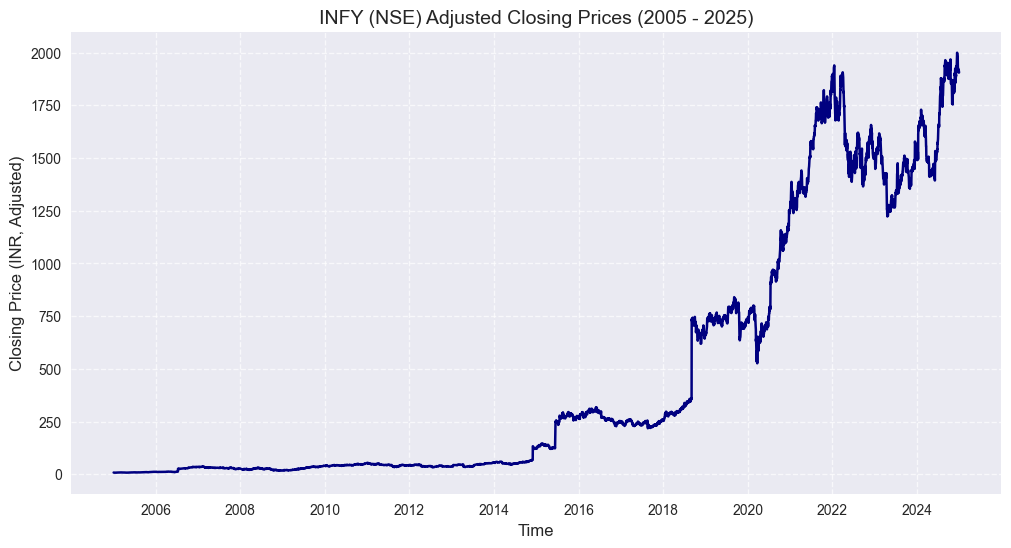

In [5]:
plt.style.use('seaborn-v0_8')
plt.figure(figsize=(12, 6))
plt.plot(df.index, df["adjusted_close"], linewidth=1.8, color='navy')

plt.title(f"{TICKER} (NSE) Adjusted Closing Prices (2005 - 2025)", fontsize=14)
plt.xlabel("Time", fontsize=12)
plt.ylabel("Closing Price (INR, Adjusted)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.gca().xaxis.set_major_locator(mdates.YearLocator(2)) 
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.show()

In [6]:
# Compute log returns
df["log_returns"] = np.log(df["adjusted_close"] / df["adjusted_close"].shift(1))

def ema(s, span):
    return s.ewm(span=span, adjust=False).mean()

def add_technical_features(df, lags=7):
    df = df.copy()
    px = df["adjusted_close"]

    # Volatility (10d, unannualized)
    df["volatility_10"] = (
        df["log_returns"].rolling(10).std()
        .fillna(df["log_returns"].expanding().std())
    )

    # RSI(14)
    delta = px.diff()
    up, down = delta.clip(lower=0), -delta.clip(upper=0)
    roll_up = up.ewm(alpha=1/14, adjust=False).mean()
    roll_down = down.ewm(alpha=1/14, adjust=False).mean()
    rs = (roll_up / (roll_down.replace(0, np.nan))).fillna(0)
    df["RSI_14"] = (100 - (100 / (1 + rs))).fillna(50)

    # MACD (12,26,9)
    ema12, ema26 = ema(px, 12), ema(px, 26)
    macd_line = ema12 - ema26
    macd_signal = ema(macd_line, 9)
    df["MACD"] = (macd_line - macd_signal).fillna(0)
    df["MACD_line"] = macd_line.fillna(0)
    df["MACD_signal"] = macd_signal.fillna(0)

    # OBV
    direction = np.sign(px.diff().fillna(0))
    obv_raw = (direction * df["Volume"]).fillna(0).cumsum()
    df["OBV"] = obv_raw.pct_change(5).fillna(0).clip(-10, 10)  # 5-day ROC, stationary

    # Lagged log returns
    for lag in range(1, lags + 1):
        df[f"lag_{lag}"] = df["log_returns"].shift(lag)

    # Multi-horizon returns
    df["ret_3d"]  = np.log(px / px.shift(3))
    df["ret_5d"]  = np.log(px / px.shift(5))
    df["ret_10d"] = np.log(px / px.shift(10))

    # Annualized vol
    df["vol_10d"] = df["log_returns"].rolling(10).std() * np.sqrt(252)
    df["vol_21d"] = df["log_returns"].rolling(21).std() * np.sqrt(252)
    df["vol_63d"] = df["log_returns"].rolling(63).std() * np.sqrt(252)

    # ATR(14)
    high_low   = df["High"] - df["Low"]
    high_close = (df["High"] - px.shift()).abs()
    low_close  = (df["Low"]  - px.shift()).abs()
    tr = pd.concat([high_low, high_close, low_close], axis=1).max(axis=1)
    df["ATR_14"] = tr.rolling(14).mean()

    # Skew/Kurtosis over 21d
    df["ret_skew_21"] = df["log_returns"].rolling(21).skew()
    df["ret_kurt_21"] = df["log_returns"].rolling(21).kurt()

    # Volume zscore
    vol = df["Volume"]
    df["vol_zscore_20"] = (vol - vol.rolling(20).mean()) / (vol.rolling(20).std() + 1e-12)

    # Vol ratio
    df["vol_ratio"] = df["vol_10d"] / (df["vol_63d"] + 1e-12)


    # ── Market context features (Nifty50) ───────────────────────────────────
    if "nifty_close" in df.columns:
        nifty = df["nifty_close"]
        nifty_ret = np.log(nifty / nifty.shift(1))
        df["nifty_ret_1d"]    = nifty_ret
        df["nifty_ret_5d"]    = np.log(nifty / nifty.shift(5))
        df["nifty_vol_21d"]   = nifty_ret.rolling(21).std() * np.sqrt(252)
        df["it_rel_strength"] = df["log_returns"] - nifty_ret  # INFY alpha vs market
        df["price_to_200sma"] = px / px.rolling(200).mean() - 1  # trend regime signal

    return df

df = add_technical_features(df, lags=7)

FEATURE_COLS = [
    "log_returns", "volatility_10", "RSI_14", "MACD", "OBV",
    "MACD_line", "MACD_signal",
    "ret_3d", "ret_5d", "ret_10d",
    "vol_10d", "vol_21d", "vol_63d", "vol_ratio",
    "ATR_14",
    "ret_skew_21", "ret_kurt_21",
    "vol_zscore_20",
] + [f"lag_{i}" for i in range(1, 8)] 


MARKET_FEATURES = [
    "nifty_ret_1d", "nifty_ret_5d", "nifty_vol_21d",
    "it_rel_strength", "price_to_200sma",
]
FEATURE_COLS = FEATURE_COLS + MARKET_FEATURES
print(f"Total features (incl. market): {len(FEATURE_COLS)}")

# Target
df["label"] = (df["log_returns"].shift(-1) > 0).astype(int)

# Final dropna and copy
df_final = df.dropna(subset=FEATURE_COLS + ["label"]).copy()

print(f"Feature engineering complete. Final shape: {df_final.shape}")
print(f"Number of features: {len(FEATURE_COLS)}")

Feature engineering complete. Final shape: (4870, 32)
Number of features: 25


In [7]:
def create_sequences(X2d, y1d, seq_length=SEQ_LEN):
    """
    Build rolling sequences of length `seq_length`.
    Returns X_seq, y_seq.
    """
    Xv = X2d.values if hasattr(X2d, "values") else np.asarray(X2d)
    yv = y1d.values if hasattr(y1d, "values") else np.asarray(y1d)
    assert len(Xv) == len(yv)
    if len(Xv) < seq_length:
        raise ValueError("Not enough rows for sequence length.")

    X_seq = np.stack([Xv[i:i+seq_length] for i in range(len(Xv) - seq_length + 1)], axis=0)

    y_seq = np.array([yv[i+seq_length-1] for i in range(len(Xv) - seq_length + 1)])

    return X_seq, y_seq
    

def get_cnn_lstm(input_shape,
                 conv_filters=64, kernel_size=3,
                 lstm_units=64,
                 dropout=0.3, rec_dropout=0.1,
                 lr=0.0005):
    """
    Builds a CNN-LSTM hybrid model:
    - CNN extracts local temporal features
    - LSTM models long-term dependencies
    - Final dense layer for binary classification
    """
    inputs = Input(shape=input_shape, name="inputs")

    # Convolutional feature extractor
    x = Conv1D(filters=conv_filters, kernel_size=kernel_size,
               activation="relu", padding="causal",
               name="conv1d")(inputs)
    x = BatchNormalization(name="bn_conv")(x)
    x = MaxPooling1D(pool_size=2, name="maxpool")(x)
    x = Dropout(dropout, name="dropout_conv")(x)

    # LSTM layer
    x = LSTM(lstm_units, return_sequences=False,
             dropout=dropout, recurrent_dropout=rec_dropout,
             name="lstm")(x)
    x = BatchNormalization(name="bn_lstm")(x)
    x = Dropout(dropout, name="dropout_lstm")(x) 

    # Output layer
    outputs = Dense(1, activation="sigmoid", name="output")(x)

    model = Model(inputs, outputs, name="cnn_lstm")
    
    # Use the Keras 3 standard Adam optimizer
    model.compile(optimizer=Adam(learning_rate=lr),
                  loss="binary_crossentropy",
                  metrics=["accuracy"])
    return model

model = get_cnn_lstm((SEQ_LEN, len(FEATURE_COLS)))
model.summary()
print("\nModel and sequence functions are defined.")

Model: "cnn_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ inputs (InputLayer)             │ (None, 28, 25)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 28, 64)         │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_conv (BatchNormalization)    │ (None, 28, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ maxpool (MaxPooling1D)          │ (None, 14, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_conv (Dropout)          │ (None, 14, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_lstm (BatchNormalization)    │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_lstm (Dropout)          │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,465 (150.25 KB)

 Trainable params: 38,209 (149.25 KB)

 Non-trainable params: 256 (1.00 KB)


Model and sequence functions are defined.


In [8]:
tscv = TimeSeriesSplit(n_splits=6, test_size=252) 

X_base = df_final[FEATURE_COLS]
y_all  = df_final["label"]

preds_cv, labels_cv, idx_cv = [], [], []
fold_rows = []
last_scaler = None

print("Starting TimeSeries Cross-Validation...")

for k, (tr_pos, va_pos) in enumerate(tscv.split(X_base)):
    print(f"--- Fold {k+1}/6 ---")
    tr_idx = X_base.index[tr_pos]; va_idx = X_base.index[va_pos]
    print(f"Train: {tr_idx.min().date()} - {tr_idx.max().date()} ({len(tr_pos)} days)")
    print(f"Val:   {va_idx.min().date()} - {va_idx.max().date()} ({len(va_pos)} days)")
    
    Xtr_2d = df_final.loc[tr_idx, FEATURE_COLS].values
    Xva_2d = df_final.loc[va_idx, FEATURE_COLS].values

    # --- Scaling ---
    sc = StandardScaler().fit(Xtr_2d)
    Xtr = sc.transform(Xtr_2d); Xva = sc.transform(Xva_2d)

    # --- Targets ---
    ytr = y_all.loc[tr_idx]; yva = y_all.loc[va_idx]

    # --- Sequence construction ---
    Xtr_seq, ytr_seq = create_sequences(Xtr, ytr, SEQ_LEN)
    Xva_seq, yva_seq = create_sequences(Xva, yva, SEQ_LEN)
    va_seq_idx = va_idx[SEQ_LEN-1:] 

    # --- Model init + training ---
    model = get_cnn_lstm((SEQ_LEN, Xtr_seq.shape[2]))
    es = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=0)
    rl = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5, verbose=0)

    model.fit(
        Xtr_seq, ytr_seq,
        validation_data=(Xva_seq, yva_seq),
        epochs=20, batch_size=64,
        verbose=0,
        callbacks=[es, rl]
    )

    # --- Predictions ---
    pv = model.predict(Xva_seq, verbose=0).flatten()
    preds_cv.extend(pv)
    labels_cv.extend(yva_seq)
    idx_cv.extend(va_seq_idx)

    # --- Metrics ---
    yhat = (pv >= 0.5).astype(int) 
    fold_rows.append({
        "fold": k+1,
        "accuracy":  accuracy_score(yva_seq, yhat),
        "precision": precision_score(yva_seq, yhat, zero_division=0),
        "recall":    recall_score(yva_seq, yhat, zero_division=0),
        "f1":        f1_score(yva_seq, yhat, zero_division=0),
        "roc_auc":   roc_auc_score(yva_seq, pv),
        "pr_auc":    average_precision_score(yva_seq, pv),
    })
    last_scaler = sc 

preds_cv = np.array(preds_cv)
labels_cv = np.array(labels_cv)
idx_cv = pd.DatetimeIndex(idx_cv)

df_folds = pd.DataFrame(fold_rows)
print("\n--- Cross-Validation Results ---")
display(df_folds)
print("\n--- Mean CV Results ---")
display(df_folds.mean(numeric_only=True))

np.save(OUTPUT_DIR/"cv_predictions.npy", preds_cv)
np.save(OUTPUT_DIR/"cv_labels.npy", labels_cv)
np.save(OUTPUT_DIR/"cv_index.npy", idx_cv.values.astype("datetime64[ns]"))

print("\nCross-validation complete. Predictions saved.")

Starting TimeSeries Cross-Validation...
--- Fold 1/6 ---
Train: 2005-04-05 - 2018-11-13 (3358 days)
Val:   2018-11-14 - 2019-11-27 (252 days)
--- Fold 2/6 ---
Train: 2005-04-05 - 2019-11-27 (3610 days)
Val:   2019-11-28 - 2020-11-27 (252 days)
--- Fold 3/6 ---
Train: 2005-04-05 - 2020-11-27 (3862 days)
Val:   2020-12-01 - 2021-12-07 (252 days)


--- Fold 4/6 ---
Train: 2005-04-05 - 2021-12-07 (4114 days)
Val:   2021-12-08 - 2022-12-12 (252 days)


--- Fold 5/6 ---
Train: 2005-04-05 - 2022-12-12 (4366 days)
Val:   2022-12-13 - 2023-12-19 (252 days)
--- Fold 6/6 ---
Train: 2005-04-05 - 2023-12-19 (4618 days)
Val:   2023-12-20 - 2024-12-30 (252 days)

--- Cross-Validation Results ---


,fold,accuracy,precision,recall,f1,roc_auc,pr_auc
0,1,0.471111,0.500000,0.823529,0.622222,0.474076,0.523378
1,2,0.533333,0.544910,0.758333,0.634146,0.525556,0.577302
2,3,0.506667,0.552632,0.512195,0.531646,0.534912,0.576408
3,4,0.448889,0.448276,0.339130,0.386139,0.458024,0.516589
4,5,0.480000,0.479452,0.972222,0.642202,0.503640,0.496836
5,6,0.493333,0.500000,0.771930,0.606897,0.433065,0.450656



--- Mean CV Results ---


fold         3.500000
accuracy     0.488889
precision    0.504212
recall       0.696223
f1           0.570542
roc_auc      0.488212
pr_auc       0.523528
dtype: float64


Cross-validation complete. Predictions saved.


In [9]:
@dataclass
class BTConfig:
    # Thresholds
    long_threshold: float = 0.55
    short_threshold: float = 0.0  # disabled — no shorting in Indian cash equities
    neutral_band: bool = True   
    # Position management
    min_hold_days: int = 0
    stop_daily: float = -0.02
    roll_loss_window: int = 10
    roll_loss_thresh: float = -0.05
    # Vol targeting
    use_vol_targeting: bool = True
    vol_window: int = 15
    target_annual_vol: float = 0.12
    max_leverage: float = 1.0  # cash delivery — no leverage available
    vol_floor: float = 1e-8
    # Costs
    cost_bps_per_turnover: float = 20.0  # NSE delivery: STT+brokerage+charges+stamp duty ~15-25 bps/side

def run_backtest_clean(
    df: pd.DataFrame,
    predictions: pd.Series | np.ndarray,
    pred_index: pd.DatetimeIndex,
    cfg: BTConfig = None,
    price_col: str = "adjusted_close",
    ret_col: str = "log_returns",
):
    """
    Leakage-safe backtest:
      - Align strictly to pred_index window
      - Signals from predictions (neutral band optional)
      - Enforce min_hold_days
      - Apply stops (daily, rolling loss)
      - Simple vol targeting
      - Transaction costs on position changes
      - Turnover & hit_rate computed
    """
    assert ret_col in df.columns, f"{ret_col} missing from df"
    cfg = cfg or BTConfig()
    win_mask = df.index.isin(pred_index)
    out = df.loc[win_mask, [ret_col, price_col]].copy()
    preds = pd.Series(predictions, index=pred_index).loc[out.index]
    out["p"] = preds
    if cfg.neutral_band:
        sig = np.select(
            [out["p"] >= cfg.long_threshold, out["p"] <= cfg.short_threshold],
            [1, 0], default=0  # No short; flat instead of short
        )
    else:
        sig = np.where(out["p"] >= cfg.long_threshold, 1, 0)  # Long or flat only
    pos = np.zeros(len(sig), dtype=float); hold = 0; rolling_pnl = []
    for i in range(1, len(sig)):
        pos[i] = pos[i-1]; hold = hold + 1 if pos[i] != 0 else 0
        pnl = pos[i-1] * out[ret_col].iloc[i]
        if pos[i-1] != 0:
            rolling_pnl.append(pnl)
            if len(rolling_pnl) > cfg.roll_loss_window: rolling_pnl.pop(0)
            if pnl <= cfg.stop_daily: pos[i] = 0; hold = 0; rolling_pnl.clear()
            elif sum(rolling_pnl) <= cfg.roll_loss_thresh: pos[i] = 0; hold = 0; rolling_pnl.clear()
        if pos[i-1] == 0:
            pos[i] = sig[i]; hold = 1 if pos[i] != 0 else 0; rolling_pnl.clear()
        elif hold < cfg.min_hold_days: pos[i] = pos[i-1]
        elif sig[i] != pos[i-1]: pos[i] = sig[i]; hold = 1 if pos[i] != 0 else 0; rolling_pnl.clear()
    out["pos_raw"] = pos
    if cfg.use_vol_targeting:
        roll_vol = out[ret_col].rolling(cfg.vol_window).std().clip(lower=cfg.vol_floor)
        target_daily = cfg.target_annual_vol / np.sqrt(252.0)
        lever = (target_daily / roll_vol).clip(upper=cfg.max_leverage)
        out["pos"] = out["pos_raw"] * lever.fillna(0.0)
    else: out["pos"] = out["pos_raw"]
    pos_change = out["pos"].diff().fillna(0.0); turnover_events = (pos_change != 0).astype(int)
    cost = (cfg.cost_bps_per_turnover / 1e4) * np.abs(pos_change)
    out["cost"] = cost
    out["strat_log_ret_gross"] = out["pos"].shift(1).fillna(0.0) * out[ret_col]
    out["strat_log_cost"] = np.log1p(-out["cost"].clip(upper=0.999999)).fillna(0.0)
    out["strat_log_ret"] = out["strat_log_ret_gross"] + out["strat_log_cost"]
    out["bh_log_ret"] = out[ret_col]
    out["strategy_equity"] = np.exp(out["strat_log_ret"].cumsum())
    out["bh_equity"] = np.exp(out["bh_log_ret"].cumsum())
    def ann_mu(x): return x.mean() * 252
    def ann_vol(x): return x.std(ddof=0) * np.sqrt(252)
    def sharpe(x): return ann_mu(x) / (ann_vol(x) + 1e-12)
    def max_dd(e): return (e / e.cummax() - 1).min()
    strat_log = out["strat_log_ret"].dropna(); bh_log = out["bh_log_ret"].dropna()
    summary = {
        "window_start": str(out.index[0].date()), "window_end": str(out.index[-1].date()),
        "bars": int(len(out)),
        "total_return": float(np.exp(strat_log.sum()) - 1), "bh_total_return": float(np.exp(bh_log.sum()) - 1),
        "cagr": float(np.exp(ann_mu(strat_log)) - 1), "bh_cagr": float(np.exp(ann_mu(bh_log)) - 1),
        "ann_vol": float(ann_vol(strat_log)), "bh_ann_vol": float(ann_vol(bh_log)),
        "sharpe": float(sharpe(strat_log)), "bh_sharpe": float(sharpe(bh_log)),
        "max_drawdown": float(max_dd(out["strategy_equity"])), "bh_max_drawdown": float(max_dd(out["bh_equity"])),
        "hit_rate": float((strat_log > 0).mean()), "turnover": int(turnover_events.sum()),
    }
    return out, summary

print("Backtest engine defined.")

Backtest engine defined.



--- Running Stage A: Threshold Sweep ---
Mean prediction from CV: 0.5241

--- Threshold Sweep Results (CV Data) ---


,threshold,sharpe,cagr,hit_rate,turnover
0,0.584,0.823350,0.028216,0.034074,102
1,0.574,0.817894,0.032287,0.047407,141
2,0.594,0.687834,0.020324,0.024444,72
3,0.604,0.673115,0.017293,0.019259,53
4,0.624,0.600907,0.012890,0.014074,40


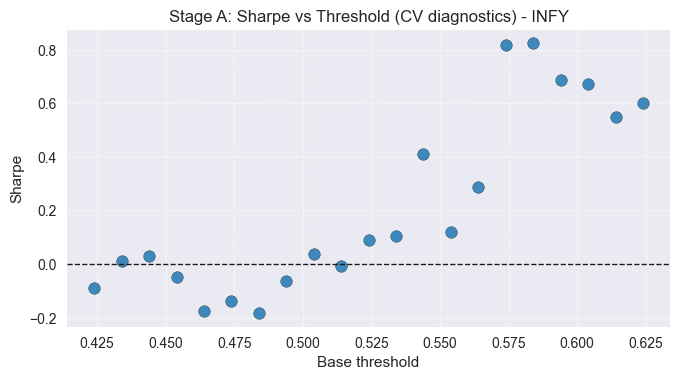

Stage A complete.


In [10]:
print("\n--- Running Stage A: Threshold Sweep ---")

pred_series_cv = pd.Series(preds_cv, index=idx_cv, name="p")

PRED_THRESHOLD_MEAN = preds_cv.mean()
print(f"Mean prediction from CV: {PRED_THRESHOLD_MEAN:.4f}")

th_grid = np.round(
    np.arange(PRED_THRESHOLD_MEAN - 0.10, PRED_THRESHOLD_MEAN + 0.101, 0.01),
    3
)
th_grid = th_grid[(th_grid > 0) & (th_grid < 1)]

rows = []
for th in th_grid:
    cfg = BTConfig(
        long_threshold=min(th + 0.02, 0.99), 
        short_threshold=0.0  # disabled — no shorting
    )
    with contextlib.redirect_stdout(io.StringIO()): 
        _, stats = run_backtest_clean(df_final, pred_series_cv, pred_index=idx_cv, cfg=cfg)
    rows.append({
        "threshold": th,
        "sharpe": stats["sharpe"],
        "cagr": stats["cagr"],
        "hit_rate": stats["hit_rate"],
        "turnover": stats["turnover"]
    })

df_sweep = pd.DataFrame(rows).sort_values("sharpe", ascending=False).reset_index(drop=True)
print("\n--- Threshold Sweep Results (CV Data) ---")
display(df_sweep.head())

plt.figure(figsize=(7, 4))
plt.scatter(df_sweep["threshold"], df_sweep["sharpe"],
            s=70, color="tab:blue", edgecolor="k", alpha=0.85)
plt.axhline(0, color="k", ls="--", lw=1)
plt.title("Stage A: Sharpe vs Threshold (CV diagnostics) - INFY")
plt.xlabel("Base threshold")
plt.ylabel("Sharpe")
plt.grid(True, ls="--", alpha=0.5)
plt.tight_layout()
plt.show()

df_sweep.to_csv(OUTPUT_DIR/"threshold_sweep_cv.csv", index=False)
print("Stage A complete.")


=== Stage H: OOS confirmatory (train+val < 2022-01-01, predict 2022-01-01+) ===
Using tuned threshold 0.5840 (LONG=0.6040, SHORT=0.5640)
Training final OOS model on all data pre-2022...

Generating final OOS equity curve...


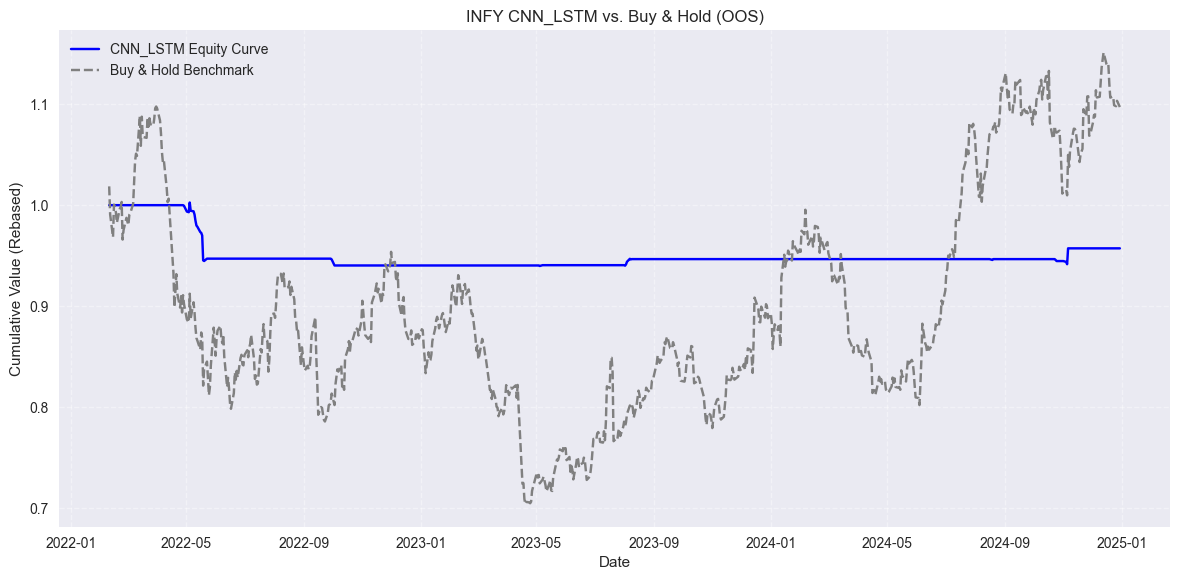


=== OOS Backtest Summary (CNN_LSTM) ===
| Metric       | Value      |
|--------------|------------|
| Window Start | 2022-02-10 |
| Window End   | 2024-12-30 |
| Bars         | 711        |
| Metric       |   CNN_LSTM | Benchmark   |
|--------------|------------|-------------|
| Total Return |     -0.043 | 0.097       |
| CAGR         |     -0.015 | 0.033       |
| Ann Vol      |      0.022 | 0.248       |
| Sharpe       |     -0.718 | 0.133       |
| Max Drawdown |     -0.063 | -0.358      |
| Hit Rate     |      0.013 |             |
| Turnover     |     33     |             |


In [11]:
print(f"\n=== Stage H: OOS confirmatory (train+val < {H_SPLIT}, predict {H_SPLIT}+) ===")

trainval_idx = df_final.index[df_final.index < H_SPLIT]  
test_idx     = df_final.index[df_final.index >= H_SPLIT] 

Xtrval2 = df_final.loc[trainval_idx, FEATURE_COLS].values
Xte2    = df_final.loc[test_idx,     FEATURE_COLS].values
ytrval  = df_final.loc[trainval_idx, "label"]
yte     = df_final.loc[test_idx,     "label"]

sc = StandardScaler().fit(Xtrval2)
Xtrval = sc.transform(Xtrval2)
Xte    = sc.transform(Xte2)

Xtrval_seq, ytrval_seq = create_sequences(Xtrval, ytrval, SEQ_LEN)
Xte_seq,    yte_seq    = create_sequences(Xte,    yte,    SEQ_LEN)
pred_index_oos = pd.DatetimeIndex(test_idx[SEQ_LEN-1:])

# ── OOS threshold: percentile-based calibration ─────────────────────────────
# The CV models and OOS model produce different output distributions.
# Using a raw probability threshold from CV on OOS predictions causes misalignment.
# Fix: map threshold to a percentile on CV preds, then apply same percentile on OOS.
try:
    BEST_THRESHOLD = float(df_sweep.iloc[0]["threshold"])
    BEST_THRESHOLD = max(0.50, min(0.65, BEST_THRESHOLD))
    # What percentile does this threshold represent in CV predictions?
    cv_preds_loaded = np.load(OUTPUT_DIR / "cv_predictions.npy")
    pct_long = float((cv_preds_loaded >= BEST_THRESHOLD).mean())  # e.g. top 14%
    print(f"CV-optimal threshold {BEST_THRESHOLD:.4f} → top {pct_long*100:.1f}% of CV predictions")
except Exception as exc:
    print(f"⚠️ Threshold error: {exc}. Using defaults.")
    BEST_THRESHOLD, pct_long = 0.57, 0.14


model = get_cnn_lstm(
    (SEQ_LEN, Xtrval_seq.shape[2]),
    conv_filters=64, kernel_size=3,
    lstm_units=64,
    dropout=0.2, lr=0.001
)

callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3)
]

print("Training final OOS model on all data pre-2022...")
hist = model.fit(
    Xtrval_seq, ytrval_seq,
    epochs=50, batch_size=64, verbose=0,
    validation_split=0.1, 
    callbacks=callbacks
)

pred_oos = model.predict(Xte_seq, verbose=0).flatten()
pred_series_oos = pd.Series(pred_oos, index=pred_index_oos, name="p")

# Percentile-calibrate: apply same top-N% cutoff as CV threshold implied
oos_long_threshold = float(np.quantile(pred_oos, 1.0 - pct_long))
oos_long_threshold = max(0.50, min(0.80, oos_long_threshold))  # sanity bounds
print(f"OOS prediction range: [{pred_oos.min():.3f}, {pred_oos.max():.3f}], mean={pred_oos.mean():.3f}")
print(f"OOS LONG threshold (percentile-calibrated): {oos_long_threshold:.4f}")

cfg = BTConfig(long_threshold=oos_long_threshold, short_threshold=0.0)  # no shorting
df_bt_oos, summary_oos = run_backtest_clean(df_final, pred_series_oos, pred_index=pred_index_oos, cfg=cfg)

oos_dir = OUTPUT_DIR/"oos_final_INFY"
oos_dir.mkdir(parents=True, exist_ok=True)
pd.DataFrame([summary_oos]).to_csv(oos_dir/"backtest_oos_summary.csv", index=False)

def _save_stage_b_equity_plot(df_bt, out_dir, model_name="Strategy"):
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.plot(df_bt.index, df_bt['strategy_equity'], label=f'{model_name} Equity Curve', color='blue')
    ax.plot(df_bt.index, df_bt['bh_equity'], label='Buy & Hold Benchmark', color='gray', linestyle='--')
    ax.set_title(f'INFY {model_name} vs. Buy & Hold (OOS)')
    ax.set_ylabel('Cumulative Value (Rebased)'); ax.set_xlabel('Date')
    ax.legend(); ax.grid(True, linestyle='--', alpha=0.4)
    fig.tight_layout(); fig.savefig(out_dir / f'equity_curve_oos.png', dpi=200); plt.show()

def print_summary_table(summary_oos, model_name="Strategy"):
    meta_df = pd.DataFrame({"Metric": ["Window Start", "Window End", "Bars"], "Value": [summary_oos["window_start"], summary_oos["window_end"], summary_oos["bars"]]})
    metrics_map = {"Total Return": ("total_return", "bh_total_return"), "CAGR": ("cagr", "bh_cagr"), "Ann Vol": ("ann_vol", "bh_ann_vol"), "Sharpe": ("sharpe", "bh_sharpe"), "Max Drawdown": ("max_drawdown", "bh_max_drawdown"), "Hit Rate": ("hit_rate", None), "Turnover": ("turnover", None)}
    rows = []
    for label, (s_key, b_key) in metrics_map.items():
        rows.append([label, f"{summary_oos.get(s_key, np.nan):.3f}", f"{summary_oos.get(b_key, np.nan):.3f}" if b_key else ""])
    summary_df = pd.DataFrame(rows, columns=["Metric", model_name, "Benchmark"])
    
    print(f"\n=== OOS Backtest Summary ({model_name}) ===")
    print(tabulate(meta_df, headers="keys", tablefmt="github", showindex=False))
    print(tabulate(summary_df, headers="keys", tablefmt="github", showindex=False))

print("\nGenerating final OOS equity curve...")
_save_stage_b_equity_plot(df_bt_oos, oos_dir, model_name="CNN_LSTM")
print_summary_table(summary_oos, model_name="CNN_LSTM")